# EXEMPLO:

##  f(x) = x^2 - x - 20

In [26]:
import math

def f(x):
    return x**2 - x - 2

def g(x):
    return math.sqrt(x + 2)

def pontoFixo(a, b, TOL, n):
    x = (a + b) / 2
    x_linha = float('nan')

    for k in range(1, n + 1):
        x_k = g(x)
        erro = abs((x_k - x_linha) / max(x_k, 1))
        x_linha = x_k

        print(k, a, b, erro, x, f(x))

        if (f(x) == 0 or erro < TOL):
            break

    return x

pontoFixo(1, 2, 1e-6, 20)

1 1 2 nan 1.5 -1.25
2 1 2 0.0 1.5 -1.25


1.5

# EXEMPLO 2:

## f(x) = x * e^x - 10
## g(x) = x - 0.5f(x)

1 0 1 0.1527777777777778 0.3472222222222222 -0.08313775291495196
2 0 1 0.00923752810166134 0.33798469412056087 -0.003253020662173256
3 0 1 0.00036144674024152224 0.33762324738031935 -0.00012373572546797718
RAIZ ENCONTRADA: 0.33762324738031935


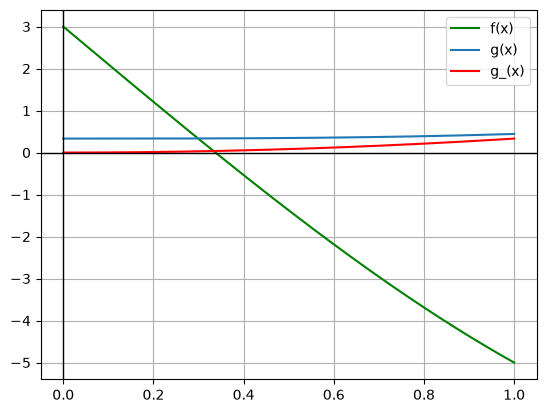

In [27]:
import numpy as np
import sympy as sy
import matplotlib.pyplot as plt

def f(x):
    return np.power(x, 3) - np.multiply(x, 9) + 3

def g(x):
    return (np.power(x, 3) + 3) / 9

def pontoFixo(a, b, TOL, n):
    x = (a + b) / 2
    x_ant = float('nan')

    for k in range(1, n + 1):
        x_ant = x
        x = g(x)
        epsilon = abs((x - x_ant) / (max(abs(x), 1)))
        print(k, a, b, epsilon, x, f(x))

        if (f(x) == 0 or epsilon < TOL):
            print(f"RAIZ ENCONTRADA: {x}")
            break

    return x

def plot(a, b, n):
    intervalo = np.linspace(a, b, n)
    plt.plot(intervalo, f(intervalo), label = 'f(x)', color = 'green')
    plt.plot(intervalo, g(intervalo), label = 'g(x)')

    x_sym = sy.Symbol('x')
    dg = sy.diff(g(x_sym), x_sym)
    dg_executavel = sy.lambdify(x_sym, dg)

    plt.plot(intervalo, dg_executavel(intervalo), label = 'g_(x)', color = 'red')
    plt.axhline(0, color = 'black', linewidth = 1, linestyle = '-')
    plt.axvline(0, color = 'black', linewidth = 1, linestyle = '-')
    plt.legend()
    plt.grid(True)
    plt.show()

pontoFixo(0, 1, 1e-3, 10)
plot(0, 1, 500) 

a função g(x) é convergente, pois a g_x < 1